### 1. Introduction
This notebook evaluates the predictive performance of the four candidate models developed in Notebook 03.

The primary objective is to assess how accurately the models identify individuals at risk of potential statin discontinuation using early statin purchasing patterns and additional patient characteristics. The evaluation uses the held-out test dataset, which was separated from the training data before model development. This dataset was not used during model fitting or cross-validation and provides an independent assessment of predictive performance on previously unseen observations. 

The evaluation focuses on five areas:

Model performance comparison: Compare the four candidate models using AUROC, Average Precision, and Brier score.

Discrimination and calibration: Examine how effectively the models distinguish between outcome groups and estimate predicted probabilities.

Risk threshold selection: Identify a classification threshold using out-of-fold predictions generated from the training data.

Model interpretation: Examine feature importance to identify predictors contributing to model predictions.

Subgroup performance: Examine predictive performance across age, sex, race/ethnicity, and insurance groups.

The findings will be used to identify the leading predictive model, assess its limitations, and determine whether its predictions may provide useful information for prioritizing additional medication adherence support. The outcome represents potential statin discontinuation based on the absence of recorded statin purchases during follow-up, rather than confirmed medication discontinuation.



### 2. Import Libraries and Set Up the Environment

The libraries required for model evaluation, visualization, and interpretation are imported.

Previously fitted models, feature definitions, data splits, and out-of-fold predictions will be loaded from the modeling artifacts saved in Notebook 03.

In [3]:
# Numerical operations
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Model evaluation
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    accuracy_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Calibration
from sklearn.calibration import CalibrationDisplay

# Model interpretation
from sklearn.inspection import permutation_importance

# File management
from pathlib import Path
import joblib

# Reproducibility
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries successfully imported.")

Libraries successfully imported.


### 3. Load Modeling Artifacts

The modeling artifacts generated in Notebook 03 are loaded into the evaluation environment. These include:

Four fitted candidate models.

Purchase-only and comprehensive feature definitions.

Training and held-out test datasets.

Actual outcome labels and patient identifiers for both datasets.

Out-of-fold predicted probabilities from the full-feature XGBoost model.

Five fitted fold models and their corresponding validation indices.


Loading these artifacts ensures that model evaluation uses the same fitted models, data partitions, feature definitions, and predictions established during model development.

Additional verification checks confirm that the loaded artifacts have the expected dimensions, that training and testing patient identifiers do not overlap, and that the saved fold models reproduce the stored out-of-fold predictions.



In [5]:
# Locate repository root
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "src" / "download_meps.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not find the repository root."
    )

# Define model directory
MODEL_DIR = ROOT / "models"

print("Repository root:", ROOT)
print("Model directory:", MODEL_DIR)

# Load fitted candidate models
fitted_models = joblib.load(
    MODEL_DIR / "candidate_models.joblib"
)

# Load feature definitions
feature_definitions = joblib.load(
    MODEL_DIR / "feature_definitions.joblib"
)

purchase_features = feature_definitions["purchase_features"]
additional_features = feature_definitions["additional_features"]
full_features = feature_definitions["full_features"]

# Load data splits
data_splits = joblib.load(
    MODEL_DIR / "data_splits.joblib"
)

X_train = data_splits["X_train"]
X_test = data_splits["X_test"]

y_train = data_splits["y_train"]
y_test = data_splits["y_test"]

ids_train = data_splits["ids_train"]
ids_test = data_splits["ids_test"]

# Load out-of-fold probabilities
oof_probabilities = joblib.load(
    MODEL_DIR / "oof_probabilities.joblib"
)

# Load fitted OOF models
oof_models = joblib.load(
    MODEL_DIR / "oof_models.joblib"
)

# Load validation indices for each fold
oof_fold_indices = joblib.load(
    MODEL_DIR / "oof_fold_indices.joblib"
)

print("All modeling artifacts successfully loaded.")

Repository root: C:\Users\chalv\statin-discontinuation
Model directory: C:\Users\chalv\statin-discontinuation\models
All modeling artifacts successfully loaded.


Verify the loaded files

In [7]:
print("Candidate models:", len(fitted_models))
print("OOF models:", len(oof_models))

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining patient IDs:", len(ids_train))
print("Testing patient IDs:", len(ids_test))

print("\nOut-of-fold predictions:", len(oof_probabilities))

# Verify dimensions
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

assert len(ids_train) == len(X_train)
assert len(ids_test) == len(X_test)

assert len(oof_probabilities) == len(y_train)

# Verify patient identifiers
assert pd.Series(ids_train).is_unique
assert pd.Series(ids_test).is_unique

assert set(ids_train).isdisjoint(set(ids_test))

# Verify five fitted fold models
assert len(oof_models) == 5
assert len(oof_fold_indices) == 5

# Verify that fold validation indices cover training observations
all_validation_indices = np.concatenate(
    oof_fold_indices
)

assert len(all_validation_indices) == len(X_train)
assert np.array_equal(
    np.sort(all_validation_indices),
    np.arange(len(X_train))
)

print("\nArtifact verification completed.")

Candidate models: 4
OOF models: 5

Training observations: 1071
Testing observations: 268

Training patient IDs: 1071
Testing patient IDs: 268

Out-of-fold predictions: 1071

Artifact verification completed.


### 4.  Test-Set Model Performance
The four candidate models are evaluated using the held-out test dataset, which was not used during model training or cross-validation.
The purpose of this evaluation is to compare how well each model generalizes to previously unseen observations.
Three performance metrics are examined:

Area Under the Receiver Operating Characteristic Curve (AUROC): Measures the model's ability to distinguish between individuals with and without potential statin discontinuation. Higher values indicate better discrimination.

Average Precision (PR-AUC): Summarizes precision across different recall levels. This metric is particularly useful when evaluating imbalanced outcomes.

Brier Score: Measures the accuracy of predicted probabilities by calculating the mean squared difference between predicted probabilities and actual outcomes. Lower values indicate better probabilistic accuracy.

All four candidate models are evaluated using the same held-out test observations. The results are used to identify the strongest candidate for subsequent evaluation.



In [9]:

# Evaluate all four candidate models on the held-out test set

test_results = []

for name, model in fitted_models.items():

    # Identify the appropriate feature set
    if "Purchase Only" in name:
        features = purchase_features
    else:
        features = full_features

    # Generate predicted probabilities
    y_prob = model.predict_proba(
        X_test[features]
    )[:, 1]

    # Calculate performance metrics
    test_results.append({
        "Model": name,
        "Test AUROC": roc_auc_score(
            y_test, y_prob
        ),
        "Test Average Precision": average_precision_score(
            y_test, y_prob
        ),
        "Brier Score": brier_score_loss(
            y_test, y_prob
        )
    })

# Organize results into a DataFrame
test_results_df = pd.DataFrame(test_results)

# Sort by AUROC
test_results_df = test_results_df.sort_values(
    by="Test AUROC",
    ascending=False
).reset_index(drop=True)

display(test_results_df.round(4))


,Model,Test AUROC,Test Average Precision,Brier Score
0,XGBoost - Full Features,0.7397,0.1953,0.0688
1,Logistic - Full Features,0.6838,0.1927,0.0698
2,XGBoost - Purchase Only,0.6015,0.1527,0.0715
3,Logistic - Purchase Only,0.5723,0.1171,0.0719


Visualizing test set performance

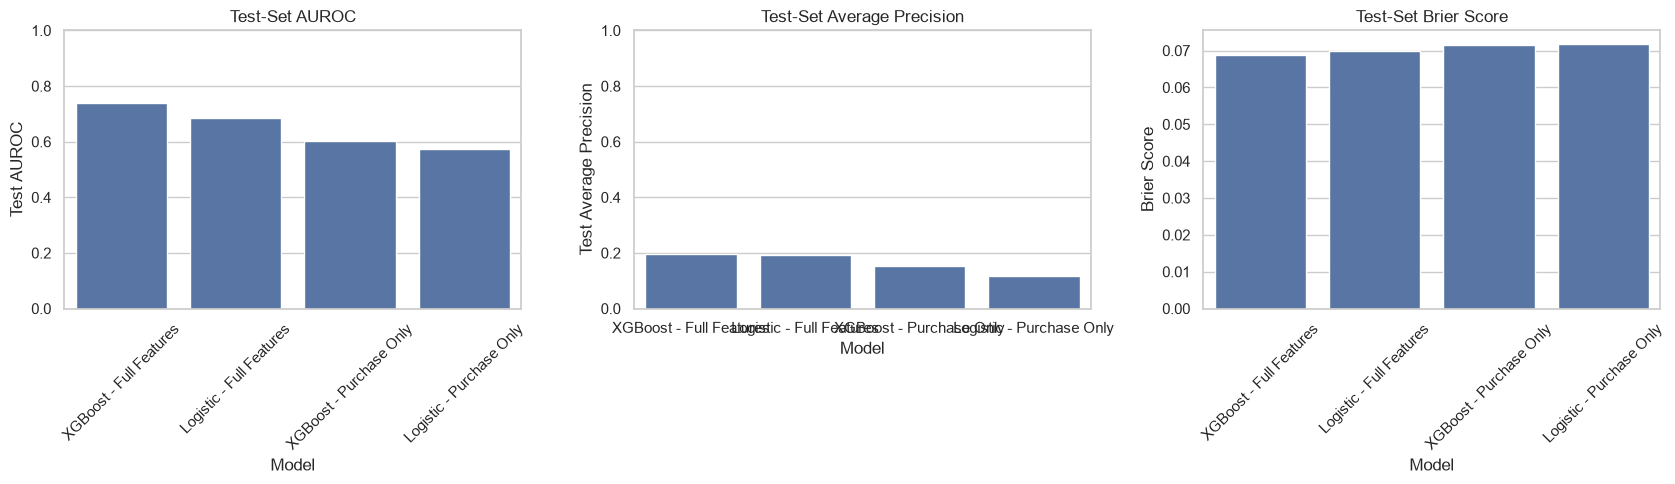

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# AUROC
sns.barplot(
    data=test_results_df,
    x="Model",
    y="Test AUROC",
    ax=axes[0]
)

axes[0].set_title("Test-Set AUROC")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=45)

# Average Precision
sns.barplot(
    data=test_results_df,
    x="Model",
    y="Test Average Precision",
    ax=axes[1]
)

axes[1].set_title("Test-Set Average Precision")
axes[1].set_ylim(0, 1)

# Brier Score
sns.barplot(
    data=test_results_df,
    x="Model",
    y="Brier Score",
    ax=axes[2]
)

axes[2].set_title("Test-Set Brier Score")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### 5. Selection of the Leading Model

The full-feature XGBoost model demonstrated the strongest overall performance across the three evaluation metrics and was identified as the leading candidate for further examination.

The model achieved the highest AUROC and average precision and the lowest Brier score among the four candidate models. These findings suggest that incorporating demographic, insurance, healthcare utilization, and health-related characteristics alongside early statin purchasing patterns provided additional predictive information.

The selected model was subsequently examined through classification threshold analysis, feature importance, calibration, and subgroup performance evaluation.

Because the held-out test results were used to compare and select the leading model, the reported performance should be interpreted as an evaluation within this dataset rather than a completely independent estimate following model selection. External validation would be necessary to establish generalizability.

In [13]:
# Select the leading candidate model

best_model_name = "XGBoost - Full Features"

best_model = fitted_models[best_model_name]

final_features = full_features

print("Selected model:", best_model_name)
print("Number of predictors:", len(final_features))


Selected model: XGBoost - Full Features
Number of predictors: 26


Generating test set probabilities

In [15]:
# Generate predicted probabilities for the model

test_probabilities = best_model.predict_proba(
    X_test[final_features]
)[:, 1]

print("Test probabilities generated.")
print("Number of predictions:", len(test_probabilities))

# Inspect predicted probability distribution
print("\nPredicted probability summary:")

display(
    pd.Series(test_probabilities).describe().round(4)
)

# Verify predicted probabilities

assert len(test_probabilities) == len(y_test)
assert np.isfinite(test_probabilities).all()
assert ((test_probabilities >= 0) &
        (test_probabilities <= 1)).all()

print("All test predictions verified.")

Test probabilities generated.
Number of predictions: 268

Predicted probability summary:


count    268.0000
mean       0.0794
std        0.0573
min        0.0203
25%        0.0397
50%        0.0619
75%        0.0948
max        0.3955
dtype: float64

All test predictions verified.


### 6. Calibration Evaluation
Calibration is examined using two approaches:

Calibration curve: Compares average predicted probabilities with observed outcome frequencies across groups of individuals.

Brier score: Measures the mean squared difference between predicted probabilities and actual outcomes. Lower values indicate better overall probabilistic accuracy.

Calibration is evaluated using the held-out test dataset to assess how accurately the selected XGBoost model estimates potential discontinuation risk.



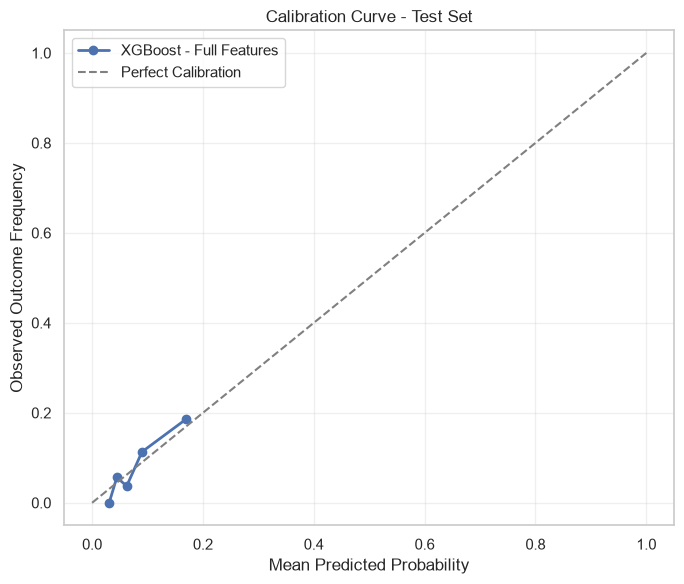

In [17]:
from sklearn.calibration import calibration_curve

# Calculate observed and predicted probabilities
fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_probabilities,
    n_bins=5,
    strategy="quantile"
)

# Plot calibration curve
plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    label="XGBoost - Full Features"
)

# Perfect calibration reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Outcome Frequency")
plt.title("Calibration Curve - Test Set")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Brier Score

In [19]:
# Calculate Brier score for selected model

final_brier_score = brier_score_loss(
    y_test,
    test_probabilities
)

print("Selected Model:", best_model_name)
print("Test Brier Score:", round(final_brier_score, 4))


Selected Model: XGBoost - Full Features
Test Brier Score: 0.0688


## 7. Classification Threshold Selection

Classification thresholds determine the probability at which an individual is classified as potentially experiencing statin discontinuation. The conventional binary classification threshold of 0.50 may be inappropriate for an imbalanced outcome, where approximately 8% of individuals in the training dataset experienced potential discontinuation.

To identify an appropriate classification threshold, out-of-fold predicted probabilities generated from the training dataset are evaluated across a range of candidate thresholds. Using out-of-fold predictions allows threshold selection without directly using the held-out test data.

The following performance metrics are examined:

Precision: The proportion of individuals classified as potential discontinuation cases who actually experienced the outcome.

Recall (Sensitivity): The proportion of actual potential discontinuation cases correctly identified.

Specificity: The proportion of individuals without potential discontinuation correctly identified.

F1-score: The harmonic mean of precision and recall, providing a balance between these two measures.

The threshold producing the highest training out-of-fold F1-score is selected as the primary candidate threshold. This approach provides a systematic basis for balancing precision and recall, although the resulting threshold does not necessarily represent the most appropriate choice for every potential clinical application.
The selected threshold is subsequently applied to the held-out test dataset to examine classification performance on previously unseen observations.



Validating out of fold predictions

In [22]:
assert len(oof_probabilities) == len(y_train)
assert np.isfinite(oof_probabilities).all()
assert ((oof_probabilities >= 0) &
        (oof_probabilities <= 1)).all()

print("Out-of-fold predictions verified.")
print("Training observations:", len(y_train))
print("Out-of-fold predictions:", len(oof_probabilities))


Out-of-fold predictions verified.
Training observations: 1071
Out-of-fold predictions: 1071


Evaluating candidate thresholds

In [24]:
# Verify saved fold models reproduce OOF predictions

reconstructed_oof = np.full(
    len(X_train),
    np.nan
)

for fold_model, validation_indices in zip(
    oof_models,
    oof_fold_indices
):

    fold_probabilities = fold_model.predict_proba(
        X_train.iloc[validation_indices][full_features]
    )[:, 1]

    reconstructed_oof[validation_indices] = (
        fold_probabilities
    )

# Verify all observations received predictions
assert np.isfinite(reconstructed_oof).all()

# Compare reconstructed and saved OOF probabilities
assert np.allclose(
    reconstructed_oof,
    np.asarray(oof_probabilities),
    atol=1e-6
)

print("Saved fold models successfully reproduce OOF predictions.")

Saved fold models successfully reproduce OOF predictions.


In [25]:
thresholds = np.arange(0.05, 0.51, 0.01)

oof_results = []

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    ).ravel()

    oof_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "True Negatives": tn
    })

oof_results_df = pd.DataFrame(oof_results)

display(oof_results_df.round(3))


,Threshold,Precision,Recall,Specificity,F1,True Positives,False Positives,False Negatives,True Negatives
0,0.05,0.100,0.756,0.404,0.176,65,587,21,398
1,0.06,0.109,0.651,0.536,0.187,56,457,30,528
2,0.07,0.125,0.593,0.637,0.206,51,358,35,627
3,0.08,0.136,0.512,0.717,0.215,44,279,42,706
4,0.09,0.143,0.453,0.763,0.218,39,233,47,752
5,0.10,0.152,0.407,0.802,0.222,35,195,51,790
6,0.11,0.161,0.360,0.837,0.223,31,161,55,824
7,0.12,0.163,0.314,0.859,0.214,27,139,59,846
8,0.13,0.162,0.267,0.879,0.202,23,119,63,866
9,0.14,0.182,0.256,0.899,0.213,22,99,64,886


Visualizing Threshold Performance

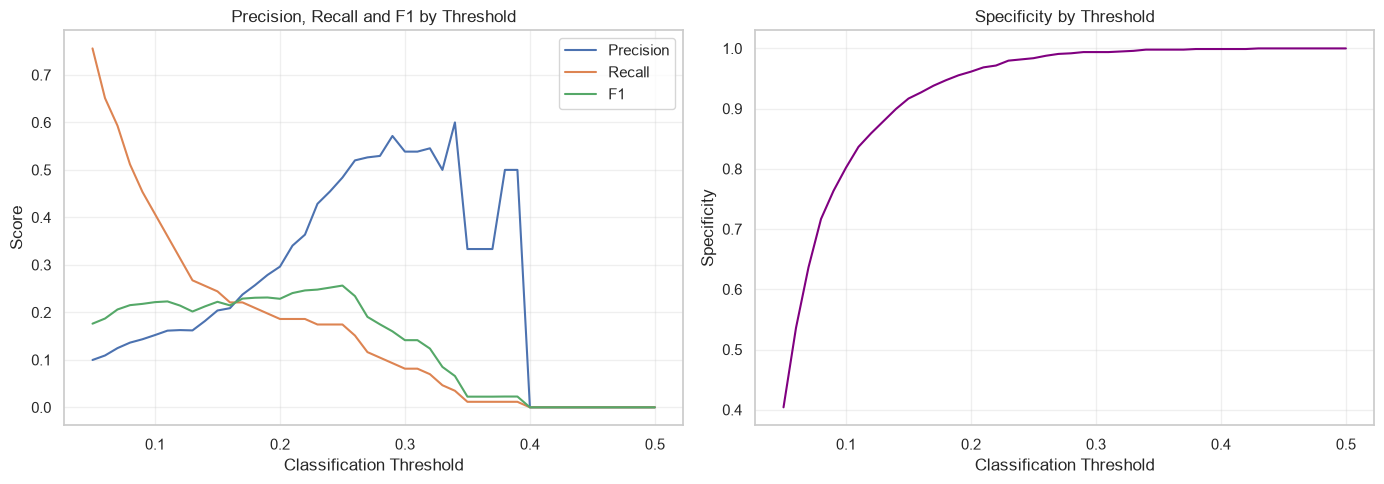

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precision, recall, and F1
for metric in ["Precision", "Recall", "F1"]:
    axes[0].plot(
        oof_results_df["Threshold"],
        oof_results_df[metric],
        label=metric
    )

axes[0].set_title("Precision, Recall and F1 by Threshold")
axes[0].set_xlabel("Classification Threshold")
axes[0].set_ylabel("Score")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Specificity
axes[1].plot(
    oof_results_df["Threshold"],
    oof_results_df["Specificity"],
    color="purple"
)

axes[1].set_title("Specificity by Threshold")
axes[1].set_xlabel("Classification Threshold")
axes[1].set_ylabel("Specificity")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Identifying the threshold with the highest F1 Score

In [29]:
best_threshold_row = oof_results_df.loc[
    oof_results_df["F1"].idxmax()
]

selected_threshold = float(
    best_threshold_row["Threshold"]
)

print("Selected threshold:", selected_threshold)

display(
    best_threshold_row.to_frame().T.round(4)
)


Selected threshold: 0.25000000000000006


,Threshold,Precision,Recall,Specificity,F1,True Positives,False Positives,False Negatives,True Negatives
20,0.25,0.4839,0.1744,0.9838,0.2564,15.0,16.0,71.0,969.0


### 8. Classification Performance on the Held-Out Test Set

The classification threshold selected using training out-of-fold predictions is applied to the predicted probabilities from the held-out test dataset to evaluate the model's ability to identify individuals with potential statin discontinuation.

A threshold of 0.25 was selected based on the highest F1-score obtained from the training out-of-fold predictions. Individuals with predicted probabilities equal to or greater than 0.25 are classified as potential discontinuation cases, while those with probabilities below this threshold are classified as continued statin purchasing.

Classification performance is evaluated using precision, recall, specificity, F1-score, and the confusion matrix. These metrics provide insight into the model's ability to identify potential discontinuation cases while accounting for false-positive and false-negative classifications.

Generating test classifications

In [32]:
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

print("Selected threshold:", selected_threshold)

print(
    "Predicted potential discontinuations:",
    test_predictions.sum()
)

print(
    "Actual potential discontinuations:",
    y_test.sum()
)

Selected threshold: 0.25000000000000006
Predicted potential discontinuations: 4
Actual potential discontinuations: 21


Calculating classification metrics

In [34]:
# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

# Calculate classification metrics

test_classification_results = pd.DataFrame([{
    "Threshold": selected_threshold,
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "Specificity": tn / (tn + fp),
    "F1 Score": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "True Positives": tp,
    "False Positives": fp,
    "False Negatives": fn,
    "True Negatives": tn
}])

display(test_classification_results.round(4))

,Threshold,Precision,Recall,Specificity,F1 Score,True Positives,False Positives,False Negatives,True Negatives
0,0.25,0.25,0.0476,0.9879,0.08,1,3,20,244


Visualizing the confusion matrix

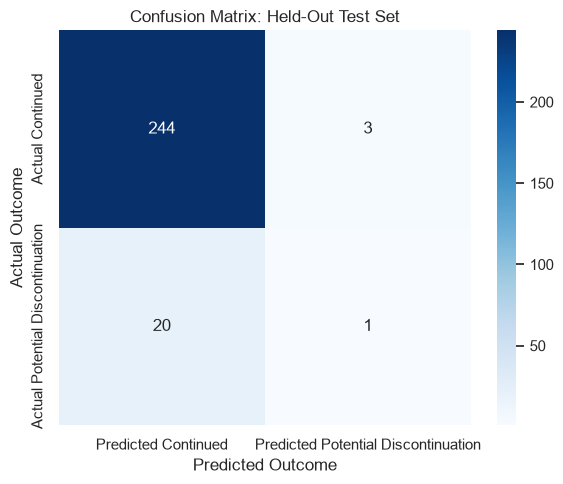

In [36]:
# Plot confusion matrix
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Predicted Continued",
        "Predicted Potential Discontinuation"
    ],
    yticklabels=[
        "Actual Continued",
        "Actual Potential Discontinuation"
    ]
)

plt.title("Confusion Matrix: Held-Out Test Set")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.tight_layout()
plt.show()

### Summary of Test Classification Performance

At the selected classification threshold of 0.25, the full-feature XGBoost model identified four individuals as potentially experiencing statin discontinuation within the held-out test dataset. Of these, one was correctly identified, resulting in a precision of 25.0%.

The model achieved a recall of 4.8%, identifying only one of the 21 individuals with observed potential discontinuation. Specificity was 98.8%, indicating that approximately 99% of individuals with continued recorded statin purchases were correctly classified.

The confusion matrix revealed three false-positive classifications and 20 false-negative classifications. These findings demonstrate that although the selected threshold resulted in relatively high specificity, the model identified very few individuals who experienced the observed outcome.

The low recall indicates that the threshold of 0.25 is relatively restrictive for identifying potential discontinuation cases. Although this threshold produced the highest F1-score among the evaluated training out-of-fold thresholds, its performance on the held-out test dataset demonstrates that the resulting balance between precision and recall did not generalize particularly well.

Overall, these findings highlight the limitations of using a single classification threshold for risk identification, particularly when the outcome is relatively uncommon. The model's predicted probabilities may provide preliminary risk-ranking information, but its classification performance at the selected threshold is insufficient to support its use as a standalone tool for prioritizing medication adherence assessments.

### 9. Feature Importance and Model Interpretation
Permutation importance is used to examine the relative contribution of individual predictors to the predictive performance of the selected XGBoost model.
The analysis evaluates how much the model's AUROC decreases when the values of a predictor are randomly permuted while all other predictors remain unchanged.
A larger decrease in AUROC indicates that the model relies more heavily on that predictor for distinguishing between individuals with and without potential statin discontinuation.
Permutation importance is calculated using the held-out test dataset, with multiple repetitions to assess the stability of the importance estimates.
The results are used to identify the predictors that contribute most to the model's predictive performance and to examine the relative importance of early statin purchasing patterns compared with demographic, insurance, healthcare utilization, and health-related characteristics.
Permutation importance measures predictive contribution rather than causal influence.



Calculating permutation importance

In [40]:
permutation_results = permutation_importance(
    best_model,
    X_test[final_features],
    y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("Permutation importance calculated.")

Permutation importance calculated.


Feature importance results

In [42]:
feature_importance_df = pd.DataFrame({
    "Feature": final_features,
    "Importance Mean": permutation_results.importances_mean,
    "Importance SD": permutation_results.importances_std
})

# Sort by mean importance

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    feature_importance_df.round(4)
)

,Feature,Importance Mean,Importance SD
0,RACETHX_round_1,0.0669,0.0230
1,distinct_drug_count_round_2,0.0410,0.0185
2,MNHLTH_round_1,0.0230,0.0228
3,statin_rx_cost_baseline_total,0.0132,0.0145
4,active_condition_count_round_1,0.0081,0.0123
5,MCARE_round_1,0.0066,0.0068
6,PMEDIN_round_1,0.0059,0.0022
7,single_fill,0.0051,0.0087
8,active_condition_count_round_2,0.0050,0.0081
9,AGE_round_1,0.0041,0.0087


Top 15 predictors

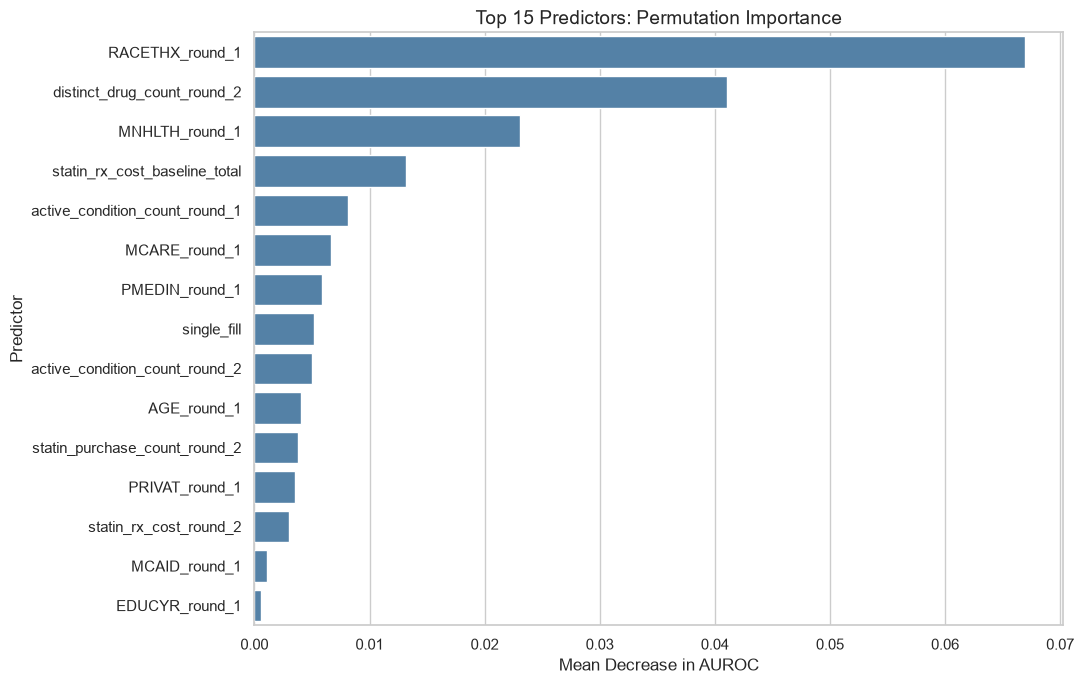

In [44]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_features,
    x="Importance Mean",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Top 15 Predictors: Permutation Importance",
    fontsize=14
)

plt.xlabel("Mean Decrease in AUROC")
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()


### Summary 

Permutation importance identified race/ethnicity (RACETHX_round_1) as the most influential predictor, with a mean AUROC decrease of 0.0669 when the variable was randomly permuted. This was followed by distinct medication count during Round 2 (0.0410) and self-reported mental health during Round 1 (0.0230).

These findings suggest that demographic characteristics, medication utilization patterns, and health-related information contributed to the predictive performance of the full-feature XGBoost model.

Insurance-related characteristics also demonstrated some predictive contribution. Medicare coverage and prescription medication coverage had mean importance values of 0.0066 and 0.0059, respectively. Baseline statin prescription costs also contributed to model performance, with a mean importance of 0.0132.

In comparison, several individual statin purchasing variables demonstrated relatively small permutation importance values. This suggests that the model's predictive performance was not driven exclusively by early statin purchasing patterns but also incorporated broader patient characteristics and medication utilization.

Several predictors demonstrated near-zero or slightly negative importance. Negative permutation importance indicates that randomly permuting a predictor did not reduce model performance on average. This may occur when predictors provide limited additional information, when their information overlaps with other variables, or because of sampling variability.

Overall, permutation importance suggests that demographic, medication utilization, and health-related characteristics contributed predictive information to the selected model. However, these findings represent predictive associations rather than causal relationships.

### 10. Model Calibration Assessment
Calibration analysis examines whether the predicted probabilities generated by the selected model correspond to the observed frequency of potential statin discontinuation.
A well-calibrated model should produce predicted probabilities that closely reflect the actual proportion of individuals experiencing the outcome. For example, among individuals assigned a predicted risk of 10%, approximately 10% should experience potential discontinuation.
Calibration is particularly important because this study aims to identify individuals who may benefit from additional medication adherence support. Although discrimination measures how effectively a model distinguishes between outcome groups, calibration determines whether its predicted probabilities provide meaningful estimates of risk.
The calibration of the selected full-feature XGBoost model is evaluated using Calibration curve and Brier Score.
Calibration is assessed using the held-out test dataset, which was not used for model selection or threshold selection.



Calibration curve

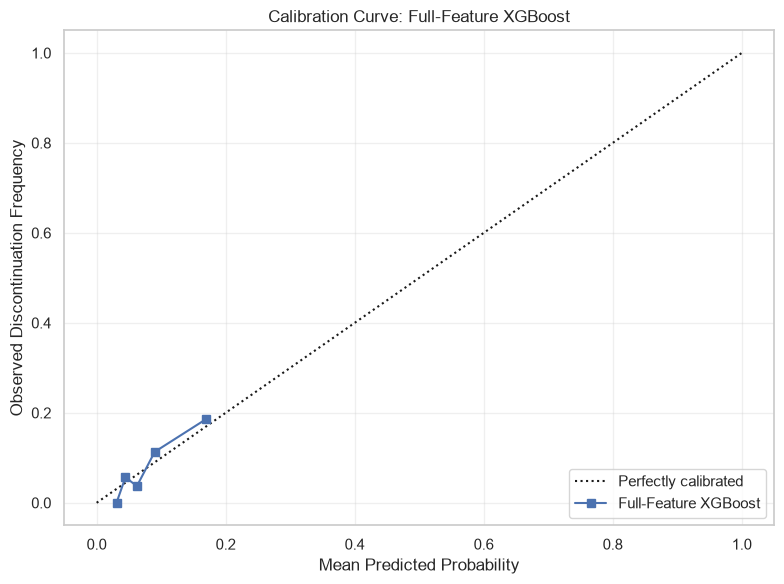

In [48]:
from sklearn.calibration import CalibrationDisplay
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_test,
    test_probabilities,
    n_bins=5,
    strategy="quantile",
    name="Full-Feature XGBoost",
    ax=ax
)

ax.set_title("Calibration Curve: Full-Feature XGBoost")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Discontinuation Frequency")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Brier Score

In [50]:
calibration_results = pd.DataFrame([{
    "Model": best_model_name,
    "Brier Score": brier_score_loss(
        y_test,
        test_probabilities
    )
}])

display(calibration_results.round(4))

,Model,Brier Score
0,XGBoost - Full Features,0.0688


In [51]:
from sklearn.calibration import calibration_curve

observed_frequency, mean_predicted_probability = (
    calibration_curve(
        y_test,
        test_probabilities,
        n_bins=5,
        strategy="quantile"
    )
)

calibration_df = pd.DataFrame({
    "Mean Predicted Probability": mean_predicted_probability,
    "Observed Outcome Frequency": observed_frequency
})

display(calibration_df.round(4))

,Mean Predicted Probability,Observed Outcome Frequency
0,0.0308,0.0000
1,0.0446,0.0566
2,0.0624,0.0370
3,0.0900,0.1132
4,0.1688,0.1852


### Summary of Calibration

The calibration assessment of the full-feature XGBoost model produced a Brier score of 0.0688 on the held-out test dataset.

The calibration curve demonstrated some agreement between predicted probabilities and observed outcome frequencies, although differences were present across the five probability groups.

The lowest-risk group had a mean predicted probability of 3.08%, compared with an observed outcome frequency of 0%. The highest-risk group demonstrated relatively close agreement, with a mean predicted probability of 16.88% and an observed outcome frequency of 18.52%.

Differences were also observed across the intermediate probability groups, suggesting that the model does not produce perfectly calibrated risk estimates across the entire probability range.

Overall, the findings suggest that the model provides some preliminary risk-ranking information, although its probability estimates should be interpreted cautiously given the relatively small number of positive outcomes in the held-out test dataset.

### 11. Subgroup Performance Evaluation
Subgroup performance evaluation examines whether the predictive performance of the selected full-feature XGBoost model varies across demographic and insurance categories.

The analysis considers age, sex, race/ethnicity, Hispanic ethnicity, general insurance coverage, Medicare, Medicaid, private insurance, and prescription medication coverage.

Evaluating performance across these groups provides insight into potential differences in model discrimination and classification performance. This is particularly important because differences in sample size, outcome prevalence, and healthcare coverage may influence predictive performance.

All subgroup analyses are conducted using the held-out test dataset and the classification threshold selected using training out-of-fold predictions.

In [54]:
# Identify subgroup variables available in X_test

required_subgroup_columns = [
    "AGE_round_1",
    "SEX_round_1",
    "RACETHX_round_1",
    "HISPANX_round_1",
    "INS_round_1",
    "MCARE_round_1",
    "MCAID_round_1",
    "PRIVAT_round_1",
    "PMEDIN_round_1"
]

available_columns = [
    col for col in required_subgroup_columns
    if col in X_test.columns
]

missing_columns = [
    col for col in required_subgroup_columns
    if col not in X_test.columns
]

print("Available subgroup variables:", available_columns)
print("Missing subgroup variables:", missing_columns)

assert len(missing_columns) == 0, (
    f"Missing subgroup variables: {missing_columns}"
)

Available subgroup variables: ['AGE_round_1', 'SEX_round_1', 'RACETHX_round_1', 'HISPANX_round_1', 'INS_round_1', 'MCARE_round_1', 'MCAID_round_1', 'PRIVAT_round_1', 'PMEDIN_round_1']
Missing subgroup variables: []


Preparing subgroups

In [56]:
test_subgroups = X_test[available_columns].copy()

# Create age groups

test_subgroups["Age Group"] = pd.cut(
    test_subgroups["AGE_round_1"],
    bins=[0, 44, 64, 74, float("inf")],
    labels=["18-44", "45-64", "65-74", "75+"]
)

# Define subgroup variables

subgroup_variables = {
    "Age": "Age Group",
    "Sex": "SEX_round_1",
    "Race/Ethnicity": "RACETHX_round_1",
    "Hispanic Ethnicity": "HISPANX_round_1",
    "General Insurance": "INS_round_1",
    "Medicare Coverage": "MCARE_round_1",
    "Medicaid Coverage": "MCAID_round_1",
    "Private Insurance": "PRIVAT_round_1",
    "Prescription Coverage": "PMEDIN_round_1"
}

print("Subgroup dataset created.")
print("Test observations:", len(test_subgroups))
print("Subgroup variables:", len(subgroup_variables))

Subgroup dataset created.
Test observations: 268
Subgroup variables: 9


Subgroup representation

In [58]:
subgroup_sizes = []

for subgroup_name, column in subgroup_variables.items():

    for group in test_subgroups[column].dropna().unique():

        mask = test_subgroups[column] == group

        y_group = y_test.loc[mask]

        subgroup_sizes.append({
            "Subgroup": subgroup_name,
            "Category": str(group),
            "Sample Size": len(y_group),
            "Positive Cases": int(y_group.sum()),
            "Negative Cases": int((y_group == 0).sum()),
            "Outcome Prevalence": y_group.mean()
        })

subgroup_sizes_df = pd.DataFrame(subgroup_sizes)

display(subgroup_sizes_df.round(3))

,Subgroup,Category,Sample Size,Positive Cases,Negative Cases,Outcome Prevalence
0,Age,75+,66,2,64,0.030
1,Age,45-64,95,11,84,0.116
2,Age,18-44,12,4,8,0.333
3,Age,65-74,95,4,91,0.042
4,Sex,2,133,9,124,0.068
5,Sex,1,135,12,123,0.089
6,Race/Ethnicity,2,182,9,173,0.049
7,Race/Ethnicity,3,37,9,28,0.243
8,Race/Ethnicity,1,34,2,32,0.059
9,Race/Ethnicity,4,9,1,8,0.111


Subgroup predicitve performance

In [60]:
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

print("Selected threshold:", selected_threshold)
print("Number of test observations:", len(test_predictions))
print("Predicted potential discontinuations:", test_predictions.sum())

Selected threshold: 0.25000000000000006
Number of test observations: 268
Predicted potential discontinuations: 4


In [61]:
subgroup_results = []

for subgroup_name, column in subgroup_variables.items():

    groups = test_subgroups[column]

    for group in sorted(groups.dropna().unique()):

        mask = (groups == group).to_numpy()

        y_group = y_test.iloc[np.where(mask)[0]]

        probabilities_group = test_probabilities[mask]
        predictions_group = test_predictions[mask]

        n = len(y_group)
        events = int(y_group.sum())

        tn, fp, fn, tp = confusion_matrix(
            y_group,
            predictions_group,
            labels=[0, 1]
        ).ravel()

        # AUROC requires both outcome classes
        auroc = (
            roc_auc_score(y_group, probabilities_group)
            if y_group.nunique() == 2
            else np.nan
        )

        # Average precision requires at least one positive case
        pr_auc = (
            average_precision_score(
                y_group,
                probabilities_group
            )
            if events > 0
            else np.nan
        )

        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        )

        subgroup_results.append({
            "Subgroup": subgroup_name,
            "Category": str(group),
            "N": n,
            "Positive Cases": events,
            "Outcome Prevalence": events / n,
            "AUROC": auroc,
            "PR-AUC": pr_auc,
            "Precision": precision_score(
                y_group,
                predictions_group,
                zero_division=0
            ),
            "Recall": recall_score(
                y_group,
                predictions_group,
                zero_division=0
            ),
            "Specificity": specificity,
            "F1": f1_score(
                y_group,
                predictions_group,
                zero_division=0
            )
        })

subgroup_results_df = pd.DataFrame(subgroup_results)

display(subgroup_results_df.round(3))

,Subgroup,Category,N,Positive Cases,Outcome Prevalence,AUROC,PR-AUC,Precision,Recall,Specificity,F1
0,Age,18-44,12,4,0.333,0.812,0.799,1.000,0.250,1.000,0.400
1,Age,45-64,95,11,0.116,0.589,0.149,0.000,0.000,0.964,0.000
2,Age,65-74,95,4,0.042,0.912,0.249,0.000,0.000,1.000,0.000
3,Age,75+,66,2,0.030,0.484,0.042,0.000,0.000,1.000,0.000
4,Sex,1,135,12,0.089,0.743,0.304,0.500,0.083,0.992,0.143
5,Sex,2,133,9,0.068,0.736,0.168,0.000,0.000,0.984,0.000
6,Race/Ethnicity,1,34,2,0.059,0.703,0.134,0.000,0.000,0.969,0.000
7,Race/Ethnicity,2,182,9,0.049,0.784,0.182,0.000,0.000,0.994,0.000
8,Race/Ethnicity,3,37,9,0.243,0.516,0.350,0.000,0.000,1.000,0.000
9,Race/Ethnicity,4,9,1,0.111,1.000,1.000,1.000,1.000,1.000,1.000


Visualizing subgroup performance

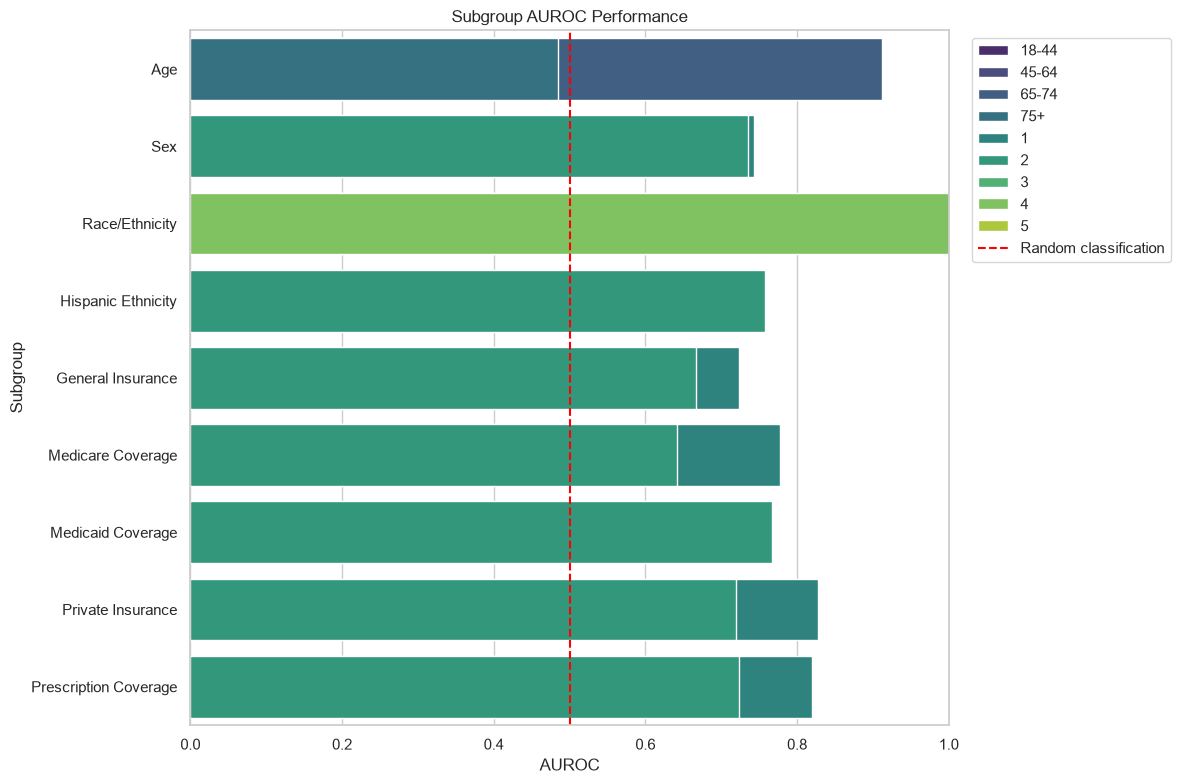

In [63]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=subgroup_results_df,
    x="AUROC",
    y="Subgroup",
    hue="Category",
    dodge=False,
    palette="viridis"
)

plt.axvline(
    0.5,
    color="red",
    linestyle="--",
    label="Random classification"
)

plt.xlim(0, 1)
plt.title("Subgroup AUROC Performance")
plt.xlabel("AUROC")
plt.ylabel("Subgroup")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

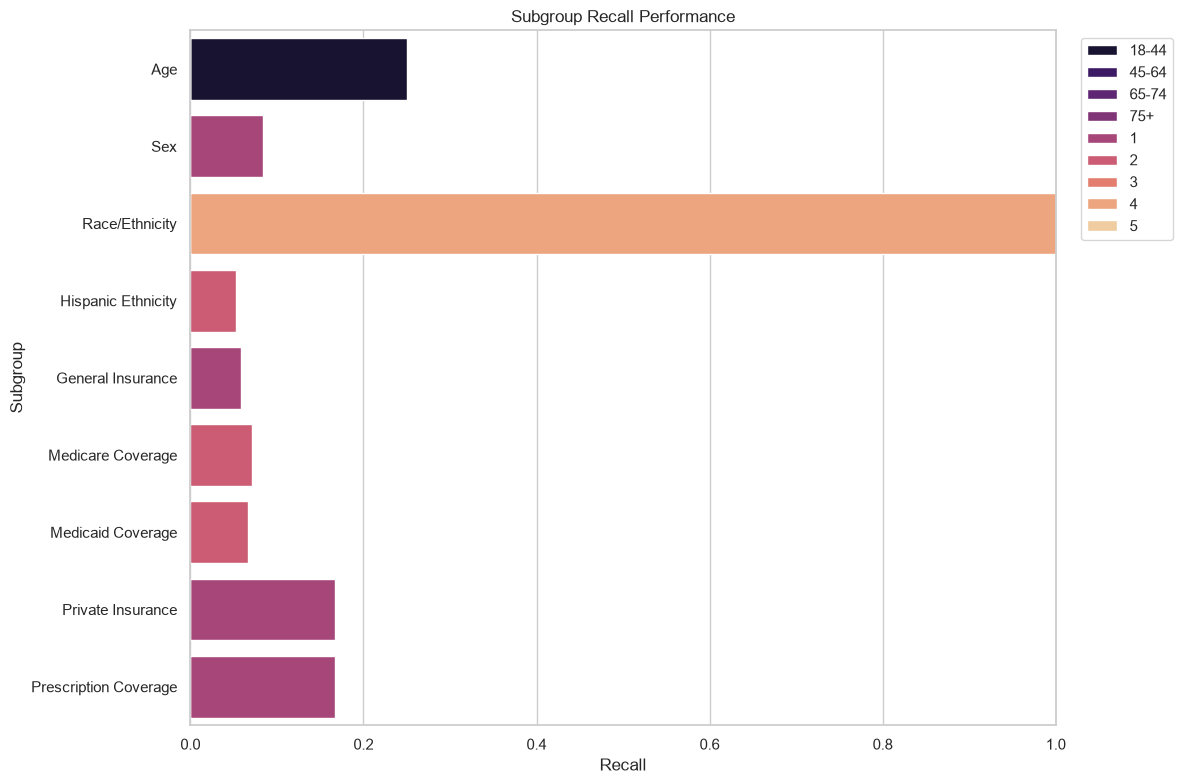

In [64]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=subgroup_results_df,
    x="Recall",
    y="Subgroup",
    hue="Category",
    dodge=False,
    palette="magma"
)

plt.xlim(0, 1)

plt.title("Subgroup Recall Performance")
plt.xlabel("Recall")
plt.ylabel("Subgroup")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Subgroup Performance Summary

Subgroup evaluation revealed variation in predictive performance across demographic and insurance-related categories.

AUROC values varied across age groups, ranging from 0.484 among individuals aged 75 and older to 0.912 among individuals aged 65–74. However, these estimates should be interpreted cautiously because several subgroups contained relatively few positive outcomes.

Classification performance also varied across subgroups. At the selected threshold of 0.25, recall was zero in several demographic and insurance categories, indicating that the model failed to identify any observed potential discontinuation cases within those groups.

Some subgroups demonstrated relatively higher recall, although the small number of predicted positive cases makes these estimates particularly sensitive to individual observations.

The findings suggest that predictive performance was not uniform across the evaluated patient characteristics. However, the relatively small subgroup sample sizes and limited number of positive outcomes prevent definitive conclusions about differences in model performance or the presence of algorithmic bias. Some high AUROC values were obtained from subgroups containing very few positive cases. Similarly, the absence of positive outcomes in certain subgroups prevented the calculation of AUROC. These findings should be interpreted as exploratory rather than definitive evidence of differences in predictive performance. 



### 12. Limitations of Model Evaluation

Several limitations should be considered when interpreting the findings of this evaluation.

## Limited number of positive outcomes

The held-out test dataset contained 268 observations, of which only 21 (7.8%) were classified as having potential statin discontinuation. This relatively small number of positive cases limits the precision and stability of performance estimates, particularly recall and precision. Consequently, individual misclassifications can substantially influence the reported metrics.

## Classification threshold selection

The classification threshold of 0.25 was selected using training-set out-of-fold predictions to maximize the F1-score. Although this approach avoids selecting the threshold directly on the held-out test data, the resulting threshold reflects a particular balance between precision and recall. It may not represent the most appropriate threshold for every potential clinical application. The relatively low recall observed on the held-out test dataset also indicates that the selected threshold did not generalize particularly well in terms of identifying positive cases.

## Model selection and evaluation

The held-out test dataset was used to compare the four candidate models and select the leading model. Consequently, subsequent performance estimates for the selected model should not be interpreted as completely independent validation following model selection. Although threshold selection was performed using training out-of-fold predictions, the test dataset was reused for calibration, feature importance, and subgroup analyses. External validation using an independent dataset would provide a more robust assessment of predictive performance and generalizability.

## Subgroup sample sizes

Subgroup evaluation revealed variation in model performance across demographic and insurance-related categories. However, several subgroups contained relatively few observations and positive outcomes. Consequently, their performance estimates may be unstable and should be interpreted cautiously. These results are exploratory and do not establish the presence or absence of algorithmic bias.

## Predictive performance and generalizability

The model was developed and evaluated using a specific observational dataset. Its performance may differ across other populations, healthcare settings, or time periods. External validation using independent data would be necessary before considering broader application.

## Observational data limitations

The analysis identifies patterns associated with potential statin discontinuation but cannot establish causal relationships. The outcome was defined using the absence of recorded statin purchases during follow-up rather than confirmed medication discontinuation. Individuals may have obtained medications through other sources or experienced gaps in recorded purchases without permanently discontinuing treatment. Predicted probabilities therefore represent estimated risk of the observed outcome rather than confirmed future patient behavior.

## Clinical interpretation

The model should be viewed as an exploratory risk-stratification approach rather than a diagnostic instrument or a replacement for clinical judgment. Its relatively low precision and limited recall at the selected classification threshold indicate that it may both identify individuals who do not experience the observed outcome and fail to identify many individuals who do. Additional clinical assessment would be necessary before interpreting any prediction as an indication of medication adherence difficulties.

### Overall Model Evaluation

Four candidate machine learning models were evaluated using a held-out test dataset to assess their ability to predict potential statin discontinuation based on early statin purchasing patterns and additional patient characteristics.

The full-feature XGBoost model demonstrated the strongest overall performance among the four candidate models, achieving a test AUROC of 0.7397, average precision of 0.1953, and Brier score of 0.0688. These results suggest that incorporating demographic, insurance, healthcare utilization, and health-related characteristics provided additional predictive information compared with models relying exclusively on statin purchasing patterns.

A classification threshold of 0.25 was selected using training out-of-fold predictions to maximize the F1-score. However, evaluation on the held-out test dataset demonstrated limited classification performance at this threshold, with recall of 4.8%, precision of 25.0%, and specificity of 98.8%. The model identified only one of the 21 individuals with observed potential discontinuation, highlighting the difficulty of identifying positive cases using the selected classification threshold.

Permutation importance identified race/ethnicity, medication diversity, and self-reported mental health as among the most influential predictors of model performance. These findings suggest that predictive information extended beyond early statin purchasing patterns, although feature importance does not establish causal relationships.

Calibration analysis demonstrated some agreement between predicted probabilities and observed outcome frequencies, although differences remained across probability groups. Subgroup evaluation also revealed variation in predictive performance across demographic and insurance categories. However, limited subgroup sample sizes and positive outcome counts restrict the reliability of these comparisons.

Overall, the findings suggest that combining early statin purchasing patterns with broader patient characteristics may improve the prediction of potential statin discontinuation compared with purchasing-only models.

Nevertheless, the relatively low recall at the selected classification threshold, limited number of positive outcomes, and variation in subgroup performance highlight important limitations. 

